# Environment Introduction
In this notebook we introduce the rules, states, observations, actions and rewards of the *King of the Hill (KotH)* environment, providing examples where possible.

## Rules

KotH Multi-Agent Reinforcement Learning (MARL) environment, as part of the melting-pot suite created by DeepMind. It is a mixed (competitive + cooperative), episodic environment where 2-8 agents must compete to capture the hill. The state is implemented as $H \times W$ grid, where each tile is occupied by an 8x8 pixel sprite. Agents are divided into 2 teams, where each agent controls its own character sprite. A character can move around the empty (black) tiles of the grid and use a zapper to paint an area in front of it to its team colour. The goal of the game is to become "king of the hill" on the grid by painting the hill area to be at least 80% of the team colour.

Below is an example game state of 23x23 grid:

![KoTH Example](img/highlighted_KotH_example.png)

Here we have 2 red characters and 2 blue characters, where the grey blocks are non-traversible walls and the purple ones indicate the current "king of the hill" (red when team red, blue when team blue, purple when neither). The hill area is not explicitly shown in the game and depends on the map configuration (more on that later). It is highlighted here to be within the yellow box for convenience.

Here is also a gameplay video: <https://www.youtube.com/watch?v=DmO2uqGBPco>

### Zapping & HP System
The aforementioned zapper can do more than just paint an area. Each character has 2HP and if they are zapped, they lose 1HP. Once they reach 0, the character disappears and respawns at their starting location. Below is an example GIF of a red character zapping a blue one until it disappears.
![Agent Zaps Opponent Example](img/agent_zaps_opponent.gif)

Additionally, characters cannot move on the opposing team's colours. To get away, a character must zap the tile in front of themselves to and move onto it. Incidentally they will also randomly regenerate their HP while staying on tiles of their colour. Below is another example of a blue character escaping and regenerating after getting zapped.

![Agent Gets Zapped and Escapes](img/agent_gets_zapped_and_escapes.gif)

### Breakable Walls
One final application of the zapper is to break cracked walls. These are wall sprites with darker patches on them. A character can break them by zapping them a few times (see example below).

![Agent Breaks Wall](img/agent_breaks_wall.gif)


### Human Play
It's recommended to try out KotH as a human player. To do so, run the following command in a terminal from the repository root:
```
python meltingpot/python/human_players/play_any_paintball_game.py --level_name mp_king_of_the_hill
```
Where the controls are:
- `WASD` keys to move the character around.
- `Q` and `E` to turn the character.
- `SPACE` to fire the zapper.
- `TAB` to switch between players.

## State & Observation
A KoTH episode lasts for 1000 steps. During each step $t$ the environment state is represented by $S_t$, which is an RGB image of the map. We receive an observation $O_t = Q_t^{(1)} \times Q_t^{(2)} ... Q_t^{(N)}$, where a $Q_t^{(i)}, i \in {1...N}$ is an agent $i$'s observation at time $t$. By default $Q_t^{(i)}$ is smaller RGB image depicting the 11x11 tiles around the agent's character. All of these variables can be described as tensors of the following shapes:
- $S_t$: $(8H,8W,3)$
- $O_t$: $(N,88,88,3)$
- $Q_t^{(i)}$: $(88,88,3)$

Here $N$ is the number of agents. The number 8 also shows up a lot here as a single tile is 8x8 in size. Lastly, the 3 refers to the number of image channels in RGB. Note also that usually $S_t$ holds more of the grid's state than a single agent's observation $Q_t^{(i)}$, which makes this environment *partially observable* per agent.

In the cells below we show code examples that generate an initial state and agent observations (i.e when $t=0$).

In [15]:
# Note, this usually generates a bunch deprecation of warnings from some dependencies
from examples.pettingzoo import meltingpot_env
from meltingpot.python.configs.substrates.king_of_the_hill import get_config
import matplotlib.pyplot as plt
import supersuit as ss
from stable_baselines3.common import vec_env
import numpy as np
from meltingpot.python.configs.substrates.king_of_the_hill import DEFAULT_ASCII_MAP

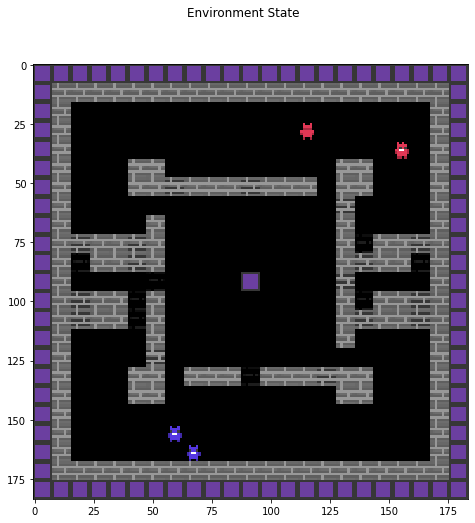

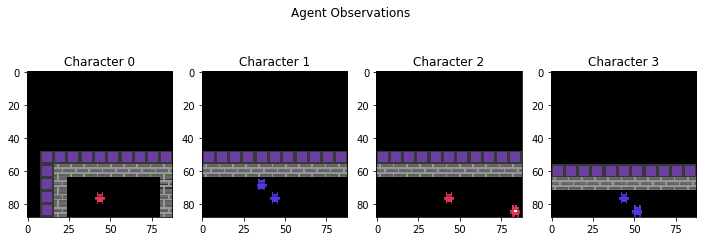

In [16]:
# Environment configuration
num_agents = 4 # Feel free to change this and see what happens
env_config = get_config(num_players=num_agents)
env = meltingpot_env.parallel_env(env_config)

# These variables are worth inspecting. They actually contain more properties than an RGB image such as position and orientation.
# However, an agent can also learn this from only the image so they are not considered.
observation = env.reset() # Observations given to the agents
state = env.state() # Entire state at the given step.

# Plotting and rendering
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(state['WORLD.RGB'], interpolation='nearest')
fig.suptitle('Environment State')
plt.show()
fig, plots = plt.subplots(nrows=1, ncols=num_agents,figsize=(num_agents*3, 4))
fig.suptitle('Agent Observations')
for i, ax in enumerate(plots):
    ax.imshow(observation[f'player_{i}']['RGB'], interpolation='nearest')
    ax.set_title(f'Character {i}')
plt.show()

If you run the above cells repeatedly you might notice that the generated map and starting positions of agents are randomised. This is because the map configuration allows for randomisation of spawn position and wall tiles. As a result, each new episode starts on a slightly different map. The default map configuration is given below. See the KotH [substrate file](../../meltingpot/python/configs/substrates/king_of_the_hill.py) for an explanation of what each character is.

In [17]:
print(DEFAULT_ASCII_MAP)


IIIIIIIIIIIIIIIIIIIIIII
IWWWWWWWWWWWWWWWWWWWWWI
IWPPP,PPPP,P,PPPP,PPPWI
IWPPP,,PP,,,,,PP,,PPPWI
IWPPP,,,,,,,,,,,,,PPPWI
IW,,,WW,,,,,,,,,WW,,,WI
IW,,,WWDWWWDWWW,WW,,,WI
IW,,,,,,,,,,,,,,D,,,,WI
IW,,,,W,GGGGGGG,W,,,,WI
IWHWWHW,GGGGGGG,WHWWHWI
IWHWWHW,GGGGGGG,WHWWHWI
IW,,,,D,GGGIGGG,D,,,,WI
IWHWWHW,GGGGGGG,WHWWHWI
IWHWWHW,GGGGGGG,WHWWHWI
IW,,,,W,GGGGGGG,W,,,,WI
IW,,,,D,,,,,,,,,,,,,,WI
IW,,,WW,WWWDWWWDWW,,,WI
IWQ,,WW,,,,,,,,,WW,,QWI
IWQQQ,,,,,,,,,,,,,QQQWI
IWQQQ,,QQ,,,,,QQ,,QQQWI
IWQQQ,QQQQ,Q,QQQQ,QQQWI
IWWWWWWWWWWWWWWWWWWWWWI
IIIIIIIIIIIIIIIIIIIIIII



### What gets fed into a NN
As mentioned earlier an agent $i$ will receive its respective observation $Q_t^{(i)}$ during each episode step $t$. We could now feed this $(88,88,3)$ tensor into a value function neural net (Deep Q learning) or policy neural net (policy gradient learning) and then start training our respective optimisation function. In practice this is usually not enough context in a partially observable environment and we prefer to feed it a window of the $M$ most recent observations: $Q_t^{(i)},Q_{t-1}^{(i)}...Q_{t-M-1}^{(i)}$ instead. This way the agent can make decisions using past information. We can express this observation window as a $(M,88,88,3)$ tensor or alternatively a $(88,88,3M)$ tensor if we stack these observations on the channel dimension.

For a visual demonstration, see the example code below where we let an agent act randomly for $M$ steps and show the observation window a neural network would receive at every step.

In [26]:
episode_len = 1000
M = 4 # number of game frames to feed to model
num_cpus = 1  # number of cpus
num_envs = 1  # number of parallel multi-agent environments
# These are mostly environment wrappers that extract the RGB image, add parallelism and support the observation window.
env = meltingpot_env.parallel_env(
    max_cycles=episode_len,
    env_config=env_config,
)
env = ss.observation_lambda_v0(env, lambda x, _: x["RGB"], lambda s: s["RGB"])
env = ss.frame_stack_v1(env, M)
env = ss.pettingzoo_env_to_vec_env_v1(env)
env = ss.concat_vec_envs_v1(
    env,
    num_vec_envs=num_envs,
    num_cpus=num_cpus,
    base_class="stable_baselines3")
env = vec_env.VecMonitor(env)
env = vec_env.VecTransposeImage(env)

In [30]:
observations = [env.reset()]
actions = [None]

def sample_actions():
    return [env.action_space.sample() for _ in range(num_agents)]

for i in range(M):
    agent_actions = sample_actions()
    actions += agent_actions
    observations.append(env.step(agent_actions)[0])

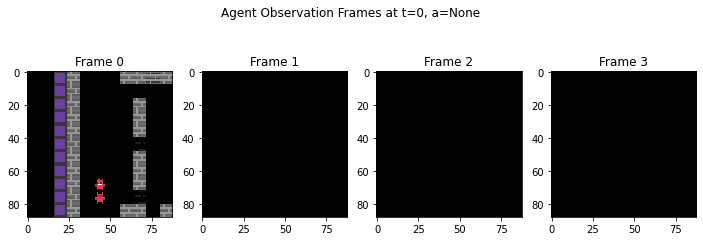

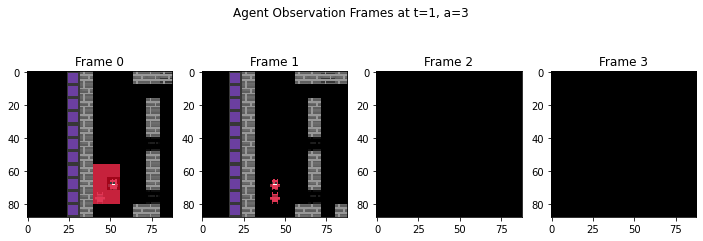

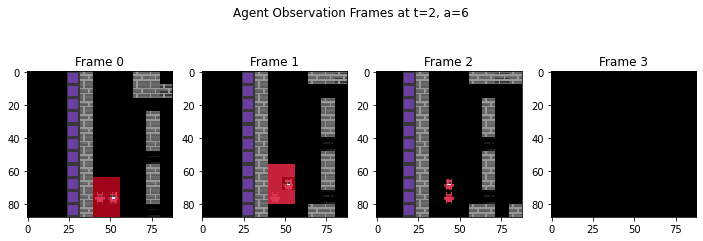

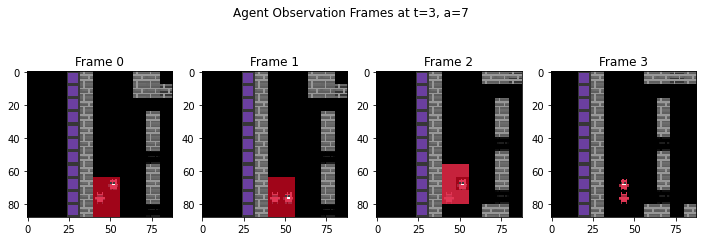

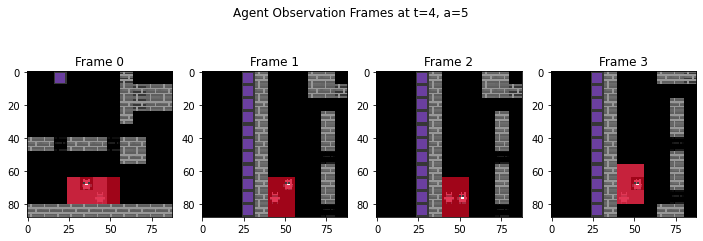

In [31]:
selected_agent = 0
for t, (o, a) in enumerate(zip(observations, actions)):
    agent_obs = o[selected_agent]
    C, H, W = agent_obs.shape # Stacked Channels,  Height, Width
    by_rgb = agent_obs.reshape(C//3,3,H,W) # Split stack into separate RGB images -->
    by_rgb = np.moveaxis(by_rgb,1,-1) # Shift channel dimension to back --> Image, Height, Width, Channels
    by_rgb = np.flip(by_rgb, axis=0) # Put frames in left-to-right order to make it easier to read

    fig, plots = plt.subplots(nrows=1, ncols=M,figsize=(M*3, 4))
    fig.suptitle(f'Agent Observation Frames at t={t}, a={a}')
    for i, ax in enumerate(plots):
        ax.imshow(by_rgb[i], interpolation='nearest')
        ax.set_title(f'Frame {i}')
    plt.show()

## Actions
We can describe an action $A_t$ in some step $t$ as a set of agent actions: $A_t = V_t^{(1)}\times V_t^{(2)}...\times V_t^{(N)}$. This follows the same structure as the agent observations where $V_t^{(i)}$ is the action taken by agent $i$ at step $t$. At any time, an agent can take one of 8 possible actions:

| **Id** | **Name**   | **Description**                                           |
|--------|------------|-----------------------------------------------------------|
| 0      | NOOP       | "No Operation" (do nothing)                               |
| 1      | FORWARD    | Move forward 1 cell with respect to the direction faced.  |
| 2      | BACKWARD   | Move backward 1 cell with respect to the direction faced. |
| 3      | STEP_LEFT  | Move left 1 cell with respect to the direction faced.     |
| 4      | STEP_RIGHT | Move right 1 cell with respect to the direction faced.    |
| 5      | TURN_LEFT  | Turn the observation 90° counterclockwise.                |
| 6      | TURN_RIGHT | Turn the observation 90° clockwise.                       |
| 7      | FIRE_ZAP   | Fire zapper to paint the surface.                         |

Most of these are fairly self-explanatory. Worth noting is that the TURN_LEFT and TURN_RIGHT actions rotate the observation instead of the character. This quite significantly changes the observation. Below an example of a character executing TURN_LEFT 4 times.

![Agent Turns Left](img/agent_turns_left.gif)

We can pass actions to the environment as follows in code:

In [32]:
agent_actions = [1] * num_agents # Every agent should move forward
print(env.action_space) # Number of possible actions per agent
print(agent_actions) # Actions taken by all agents
observation, reward, done, info = env.step(agent_actions) #executing the agent actions

Discrete(8)
[1, 1, 1, 1]


When considering the above example, it's worth asking: does it always make sense for an agent to move forward? For example, when an agent is facing a wall, it would not move anywhere and effectively accomplish nothing. We refer to these as *invalid actions* which are actions the environment allows, but do not change the state in any meaningful way. Often we filter invalid actions to reduce the possible action space. This allows an agent to learn faster.

## Rewards
When the environment transitions from $S_t$ to $S_{t+1}$ it may give each agent $i$ a reward $R_{t+1}^{(i)}$. In pretty much all reinforcement learning tasks, the goal of an agent is to maximise the cumulative expected reward also referred to as the *expected return*. In KotH each agent on a team receives the same, shared reward. During the state transition, rewards are assigned as follows to each team based on who is "king of the hill":

| **King of the Hill** | **Team** | **Reward** |
|----------------------|----------|------------|
| Nobody               | Red      | 0          |
| Nobody               | Blue     | 0          |
| Red                  | Red      | +1         |
| Red                  | Blue     | -1         |
| Blue                 | Red      | -1         |
| Blue                 | Blue     | +1         |

Which can be summarised by "the team that controls the hill is rewarded, while the other team is punished". So for example, if our episode is 1000 steps long and the red team holds it the entire time, then its return is 1000, whereas the blue team's return is -1000. In code this reward can be obtained as an additional property when calling `observation, reward, _, _ = env.step(agent_actions)`, but this is a bit difficult to demonstrate without implementing an agent.

It should be noted that these rewards can be reconfigured and are effectively training hyper-parameters. For example, we could choose to give a +0.5 reward to agents team for zapping enemy agents. The sparsest form of reward is giving either -1 or 1 to a team at the end of an episode, but this usually very difficult to train on.